# Compare electrophysiological measures of L5 cell to Kalmbach 2021 (Human L5 cells)

In [67]:
# Compare l5 cell to electrophysio measures by Kalmbach et al., 2021

import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
from scipy import signal
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_cells_dev/figures/l5_ET_tuning/'
# import os
# os.mkdir(figpth)

import pandas as pd
import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_cells_dev/utils')
from cell_builder_utils import l5_params, _get_dends, _get_pyr_soma, Cell
from hay_mechs_utils import Mechs, Ih_condu_hay, linear_gbar, Ih_condu_apical
from plot_utils import fig_conductances, fig_compartments
from functools import partial
import os
from hnn_core.viz import plot_cell_morphology

plt.rcParams['svg.fonttype'] = 'none'

# Set global font sizes
plt.rcParams['font.size'] = 16          # Default text size
plt.rcParams['axes.titlesize'] = 16      # Title size
plt.rcParams['axes.labelsize'] = 16      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 16    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 16     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 16     # Legend text


In [68]:
# def Ih_condu_apical(gsoma, x):

#     sl = 1.1
#     a = 5 # 2.087
#     return gsoma * (-0.8696 + a * np.exp(sl*(x/323)))

# def linear_gbar(gbar_min, gbar_max, xkink, x):

#     return gbar_min + (gbar_max-gbar_min) * np.min([xkink, x]) / xkink

from hay_mechs_utils import Mechs, Ih_condu_hay, linear_gbar


In [69]:
hay_model_params = {'soma': {'NaTs2_t': 20_400e-4/2*1.2,
                                'SKv3_1': 6_930e-4/2,
                                'Nap_Et2': 17.2e-4/2*0.11,
                                'Ca_HVA': 9.92e-04/2,
                                'Ca_LVAst': 34.3e-4/2,
                                'SK_E2': 441e-4*10,                      # increase this one to get burst followed by regular firing
                                'Ih': 1e-4/2,
                                'Im': 1e-4,
                                'K_Pst': 22.3e-4/2,#*0.1,
                                'K_Tst': 812e-4/2,#*0.1,
                                'pas': {'g': .338e-4/2,
                                          'e': -90}},
                        'basal': {'NaTs2_t': partial(linear_gbar,20_400e-4/2*0.01,0,255),
                                'SKv3_1': partial(linear_gbar,0,0.000261/2*1,255),
                                  'Ih': 5.14e-5/2,
                                  'pas': {'g': 1.75e-5/2,
                                          'e': -90}},
                        'dend': {'NaTa_t': 0.0213/2,
                                'SKv3_1': 0.000261/2,
                                'Ca_HVA': partial(linear_gbar, 2.78e-5/2*1., 2.78e-5/2*6.6, 1500),
                                'Ca_LVAst': partial(linear_gbar, 93.5e-6/2, 93.5e-6/2*2.75, 1500),
                                'SK_E2': 0.0012/2*4,#*2,#*1.6,
                                'Ih': partial(Ih_condu_hay, 1e-4/2),
                                'Im': 0.0000675/2,
                                'K_Pst': 0,
                                'K_Tst': 0,
                                'pas': {'g': 0.0000589/2,
                                          'e': -85}}}



## Resting membrane potential

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.


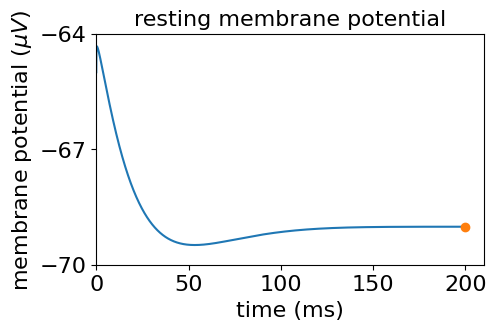

In [70]:
# Find resting membrane potential
section_params, end_pts, cell_tree = l5_params()

# build sections
section_names = list(end_pts.keys())

v_init = {'soma': -65,
            'basal_1': -64,
            'basal_2': -64,
            'basal_3': -64,
            'apical_oblique': -64,
            'apical_trunk': -64,
            'apical_1': -64,
            'apical_2': -60,
            'apical_tuft': -58}

sections = _get_dends(section_params, 'L5Pyr', section_names, end_pts, v_init=v_init)
sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr', end_pts['soma'], v_init=v_init['soma'])

mech_class = Mechs(pth_mod)

# build model
hotzone = [1500, 2000]
l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(200 * ms)

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(t,soma_voltg)
ax.plot(t.as_numpy()[-3],soma_voltg[-3],'o')
ax.set_xlabel('time (ms)')
ax.set_ylabel('membrane potential ($\mu V$)')
ax.set_title('resting membrane potential')
ax.set_yticks(np.arange(-70, -61, 3))
ax.set_xlim([0, 210])
ax.set_xticks(np.arange(0, 210, 50))

fig.savefig(os.path.join(figpth, 'rmp.png'))
fig.savefig(os.path.join(figpth, 'rmp.svg'), format='svg')

rmp = soma_voltg[-3]



## Rebound slope

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_23741/3482176015.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  peak_heights[i] = pk[1]['peak_heights']
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_23741/3482176015.py:54: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  ax[0].plot(t[int(steady_idx+pk[0])], peak_heights[i], 'o', color='tab:red')


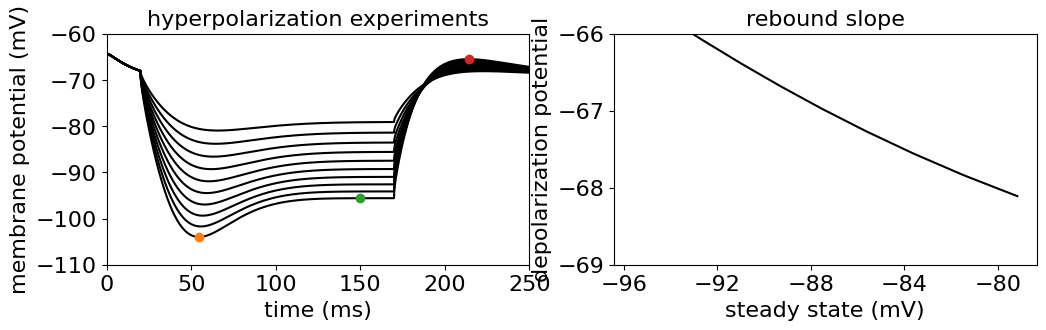

In [71]:
# Rebound slope: amplitude of rebound as a function of steady state membrane potential (during hyperpolarization)

from scipy.signal import find_peaks

fig, ax = plt.subplots(1,2, figsize = (12, 3))


ampl = np.linspace(-.3, -1.0, 10)


soma_v = np.zeros((len(ampl),int(1/h.dt*250+1)))
peak_heights = np.zeros_like(ampl)
steady_state = np.zeros_like(ampl)
min_membr_pot = np.zeros_like(ampl)
sag_ratio = np.zeros_like(ampl)
for i,amp in enumerate(ampl):

    l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l5pyr.build()
    l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)


    stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim.delay = 20
    stim.dur = 150
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize()
    h.continuerun(250 * ms)

    steady_idx = np.argmin(np.abs(t-150))
    soma_v[i] = soma_voltg.as_numpy()

    pk = find_peaks(soma_v[i][steady_idx:], height=[-70, 50])
    if len(pk[1]) > 1:
        peak_heights[i] = pk[1]['peak_heights'][0]
    else:
        peak_heights[i] = pk[1]['peak_heights']
    
    min_membr_pot[i] = np.min(soma_v[i])

    steady_state[i] = soma_v[i][steady_idx]

    
    ax[0].plot(t, soma_voltg, color='k')
    if i == len(ampl)-1:
        ax[0].plot(t[np.argmin(soma_v[i])], min_membr_pot[i], 'o', color='tab:orange')
        ax[0].plot(t[steady_idx], steady_state[i], 'o', color='tab:green')
        ax[0].plot(t[int(steady_idx+pk[0])], peak_heights[i], 'o', color='tab:red')

ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_xlabel('time (ms)')
ax[0].set_title('hyperpolarization experiments')
ax[0].set_xlim([0, 250])
ax[0].set_ylim([-110, -60])

ax[1].plot(steady_state, peak_heights, color='k')
ax[1].set_yticks(np.arange(-69,-65,1))
ax[1].set_xticks(np.arange(-96,-78,4))

ax[1].set_ylim([-69, -66])
ax[1].set_xlabel('steady state (mV)')
ax[1].set_ylabel('depolarization potential')
ax[1].set_title('rebound slope')
rebound_slope = np.polyfit(steady_state, peak_heights,1)[0]

# Sag ratio - see Methods Kalmbach et al., 2021
inp_res_max = np.polyfit(ampl,min_membr_pot,1)[0]
inp_res_steady = np.polyfit(ampl,steady_state,1)[0]

sag_ratio = inp_res_max/inp_res_steady

fig.savefig(os.path.join(figpth, 'rebound_slope.png'))
fig.savefig(os.path.join(figpth, 'rebound_slope.svg'), format='svg')



## Action potential measures

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_23741/2388854090.py:51: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  idx1 = np.argmin(np.abs(v_soma.as_numpy()[ap_thresh_idx:int(ap)]-half_max))
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_23741/2388854090.py:52: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  idx2 = np.argmin(np.abs(v_soma.as_numpy()[int(ap):int(ap_trough+np.argmax(v_soma))]-half_max))
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_23741/2388854090.py:56: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a sin

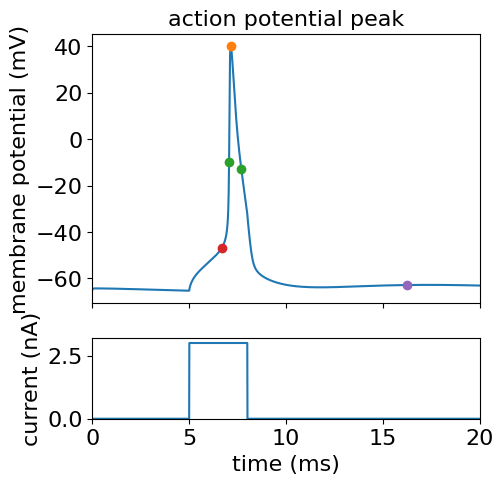

In [72]:
# AP peak

l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 3
stim.amp = 3
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
iclamp = h.Vector().record(stim._ref_i)

h.celsius = 37
h.dt = .01
h.finitialize()
h.continuerun(20 * ms)

ap, properties = find_peaks(v_soma.as_numpy(), height=0, width=0)

v_grad = np.gradient(v_soma)
smooth_v = signal.savgol_filter(np.diff(v_soma.as_numpy), 101, 3)

ap_thresh_idx = np.where(smooth_v/np.diff(t.as_numpy()) > 20)[0][0]+1

ap_thresh = v_soma[ap_thresh_idx]

if len(ap) > 0:
    ap_peak = properties['peak_heights'][0]
else:
    ap_peak = v_soma[-1]

fig, ax = plt.subplots(2,1, figsize=(5,5), height_ratios=[1,.3], sharex=True)
ax[0].plot(t, v_soma)
ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_title('action potential peak')
ax[0].plot(t[np.argmax(v_soma)], ap_peak, 'o', color='tab:orange')


ax[0].plot(t[ap_thresh_idx], ap_thresh, 'o', color='tab:red')



# Width at halfmax
ap_trough = np.argmin(v_soma.as_numpy()[np.argmax(v_soma):])

half_max = np.min(v_soma.as_numpy()) + (np.max(v_soma.as_numpy())-np.min(v_soma.as_numpy()))/2
idx1 = np.argmin(np.abs(v_soma.as_numpy()[ap_thresh_idx:int(ap)]-half_max))
idx2 = np.argmin(np.abs(v_soma.as_numpy()[int(ap):int(ap_trough+np.argmax(v_soma))]-half_max))
v2 = np.gradient(np.gradient(v_soma.as_numpy()))

ax[0].plot(t.as_numpy()[idx1+ap_thresh_idx],v_soma.as_numpy()[idx1+ap_thresh_idx],'o', color='tab:green')
ax[0].plot(t.as_numpy()[idx2+int(ap)],v_soma.as_numpy()[idx2+int(ap)],'o', color='tab:green')

ax[1].plot(t,iclamp)
ax[1].set_xlabel('time (ms)')
ax[1].set_xticks(np.arange(0, 25, 5))
ax[1].set_xlim([0, 20])
ax[1].set_ylabel('current (nA)')
ax[1].set_ylim([0, 3.2])
ap_hw = t.as_numpy()[idx2+int(ap)]-t.as_numpy()[idx1+ap_thresh_idx]

f_AHP = np.min(v_soma.as_numpy()) - ap_thresh
v2 = np.gradient(np.gradient(v_soma.as_numpy()))

ahp, properties = find_peaks(-v2)
f_AHP = np.min(v_soma.as_numpy()[ahp[-1]]) - ap_thresh
ax[0].plot(t.as_numpy()[ahp[-1]], v_soma.as_numpy()[ahp[-1]], 'o', color='tab:purple')

fig.savefig(os.path.join(figpth, 'ap_measures.svg'))
fig.savefig(os.path.join(figpth, 'ap_measures.png'), format='svg')



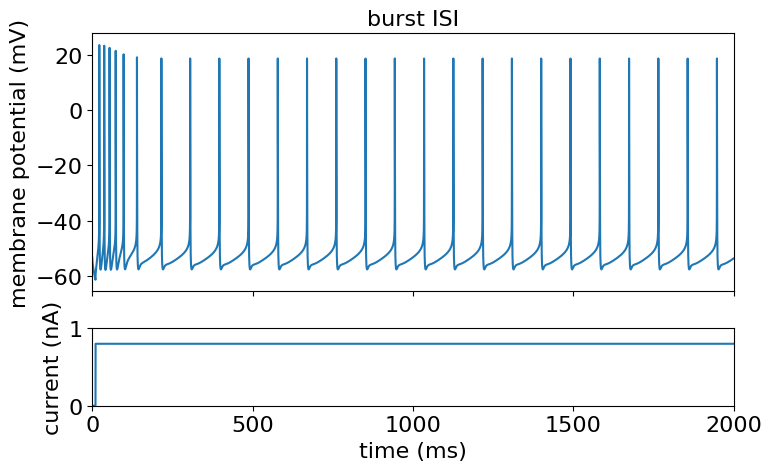

In [73]:
# burst ISIs
# 50 ms ISI (burst)

l5pyr = Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 10
stim.dur = 2000
stim.amp = .8

t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
iclamp = h.Vector().record(stim._ref_i)
h.celsius = 37
h.finitialize()
h.continuerun(50 * ms)

#soma_voltg = soma_voltg.as_numpy()

spk, prop = signal.find_peaks(soma_voltg, height=0)


min_burst_isi = np.mean(np.diff(t.as_numpy()[spk]))


t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(2000 * ms)

fig, ax = plt.subplots(2,1,height_ratios=[1,0.3],figsize=(8,5), sharex=True)
ax[0].plot(t, soma_voltg)
ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_title('burst ISI')
ax[1].plot(t, iclamp)
ax[1].set_ylim([0,1])
ax[1].set_xlabel('time (ms)')
ax[1].set_xticks(np.arange(0, 2001, 500))
ax[1].set_xlim([0, 2000])
ax[1].set_ylabel('current (nA)')
fig.tight_layout()
fig.savefig(os.path.join(figpth, 'burst_isi.png'))
fig.savefig(os.path.join(figpth, 'burst_isi.svg'), format='svg')

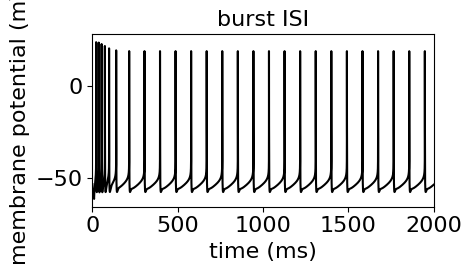

In [74]:
fig, ax = plt.subplots(figsize=(5,3))
ax.plot(t, soma_voltg, color='k')
ax.set_ylabel('membrane potential (mV)')
ax.set_xlim([0, 2000])
ax.set_xticks(np.arange(0, 2001, 500))
ax.set_title('burst ISI')
ax.set_xlabel('time (ms)')
fig.tight_layout()
fig.savefig(os.path.join(figpth, 'burst_isi.png'))
fig.savefig(os.path.join(figpth, 'burst_isi.svg'), format='svg')

In [75]:
min_burst_isi 

np.float64(14.930000000002742)

## FI slope

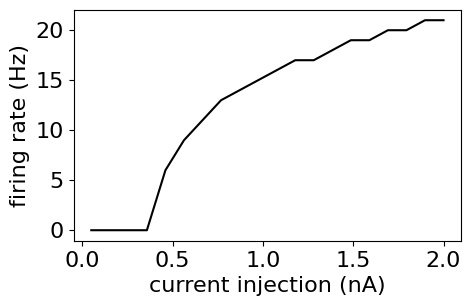

In [76]:
# FI slope
del l5pyr

ampls = np.linspace(.05,2,20)

F = np.zeros_like(ampls)
for i,amp in enumerate(ampls):

    l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)

    l5pyr.build()
    l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)


    stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim.delay = 1
    stim.dur = 1000
    stim.amp = amp

    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize()
    h.continuerun(1001 * ms)

    soma_voltg = soma_voltg.as_numpy()

    F[i] = len(signal.find_peaks(soma_voltg, height=0)[0])

FI_slope = np.diff(np.array(F))/np.diff(ampls)[0]
pA = 0.001

fig, ax = plt.subplots(figsize=(5,3))
ax.plot(ampls, F, color='k')
ax.set_ylabel('firing rate (Hz)')
ax.set_xlabel('current injection (nA)')
# ax.set_xlim([0, 2])
# ax.set_xticks(np.arange(0, 2.1, .5))
max_fi = max(FI_slope)*pA
fig.savefig(os.path.join(figpth, 'FI_slope.png'))
fig.savefig(os.path.join(figpth, 'FI_slope.svg'), format='svg')



In [77]:
FI_slope

array([ 0.        ,  0.        ,  0.        , 58.46153846, 29.23076923,
       19.48717949, 19.48717949,  9.74358974,  9.74358974,  9.74358974,
        9.74358974,  0.        ,  9.74358974,  9.74358974,  0.        ,
        9.74358974,  0.        ,  9.74358974,  0.        ])

## Resonance in response to chirp stimulus

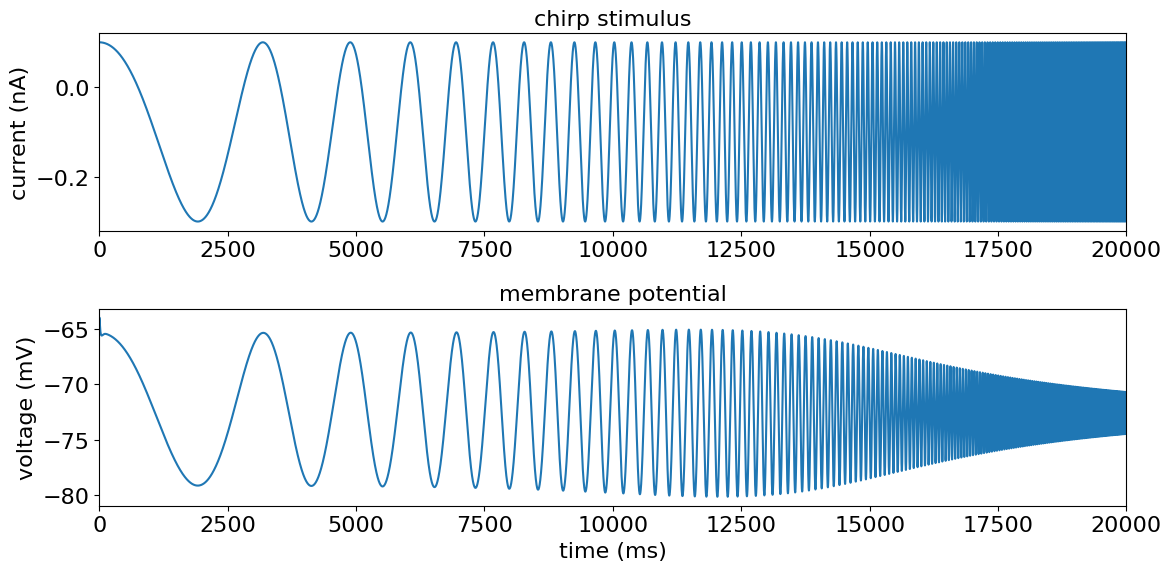

In [78]:
# Chirp stimulus


from scipy.signal import chirp
l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)

l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

# set up clamp
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 0#100

# Define simulation parameters
h.tstop = 20_100  # Simulation duration in ms
stim.dur = h.tstop #- 100  # Stimulus duration in ms
h.dt = 0.1    # Time step

# Create a chirp stimulus (linear frequency sweep)
t_chirp = np.arange(0, stim.dur, h.dt)  # Time vector

# Kalmbach et al: linear increase from 1-15 Hz over
f0 = 0.2  # Initial frequency in Hz
f1 = 40  # Final frequency in Hz
A = .2 # Amplitude of the chirp in nA - adjusted to achieve a voltage deflection of ~10mV peak to peak 

# Chirp signal: I(t) = A * sin(2 * pi * f(t) * t)
#f_t = f0 + (f1 - f0) * t_chirp / h.tstop  # Linearly increasing frequency
#chirp_signal = A * np.sin(2 * np.pi * f_t * t_chirp/1000)  + .2# Convert ms to seconds

# logarithmic chirp
chirp_signal = A * chirp(t_chirp/1000, f0, 20, f1, method='log') - 0.1


stim.amp = 0  # We'll use Vector.play() to set the amplitude
# Apply the chirp stimulus using a Vector and play()
stim_vec = h.Vector(chirp_signal)
t = np.arange(0, stim.dur, h.dt)
time_vec = h.Vector(t)
stim_vec.play(stim._ref_amp, time_vec, 1)

# Record membrane potential
v_rec = h.Vector()
v_rec.record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
t_rec = h.Vector().record(h._ref_t)
# Run the simulation
h.finitialize()  # Initialize membrane potential
h.continuerun(h.tstop)

# Plot results

fig, ax = plt.subplots(2,1, figsize=(12,6))

ax[0].plot(t, chirp_signal)
ax[0].set_ylabel('current (nA)')
ax[0].set_title('chirp stimulus')
ax[0].set_xlim([0,20000])

ax[1].plot(t_rec, v_rec.as_numpy(), label='Membrane Potential')
ax[1].set_xlabel('time (ms)')
ax[1].set_ylabel('voltage (mV)')
ax[1].set_title('membrane potential')
ax[1].set_xlim([0,20000])
fig.tight_layout()

#fig.savefig(os.path.join(figpth, 'chirp_stim.png'))


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_23741/848017242.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  maxf = int(np.where(freq == 40)[0])


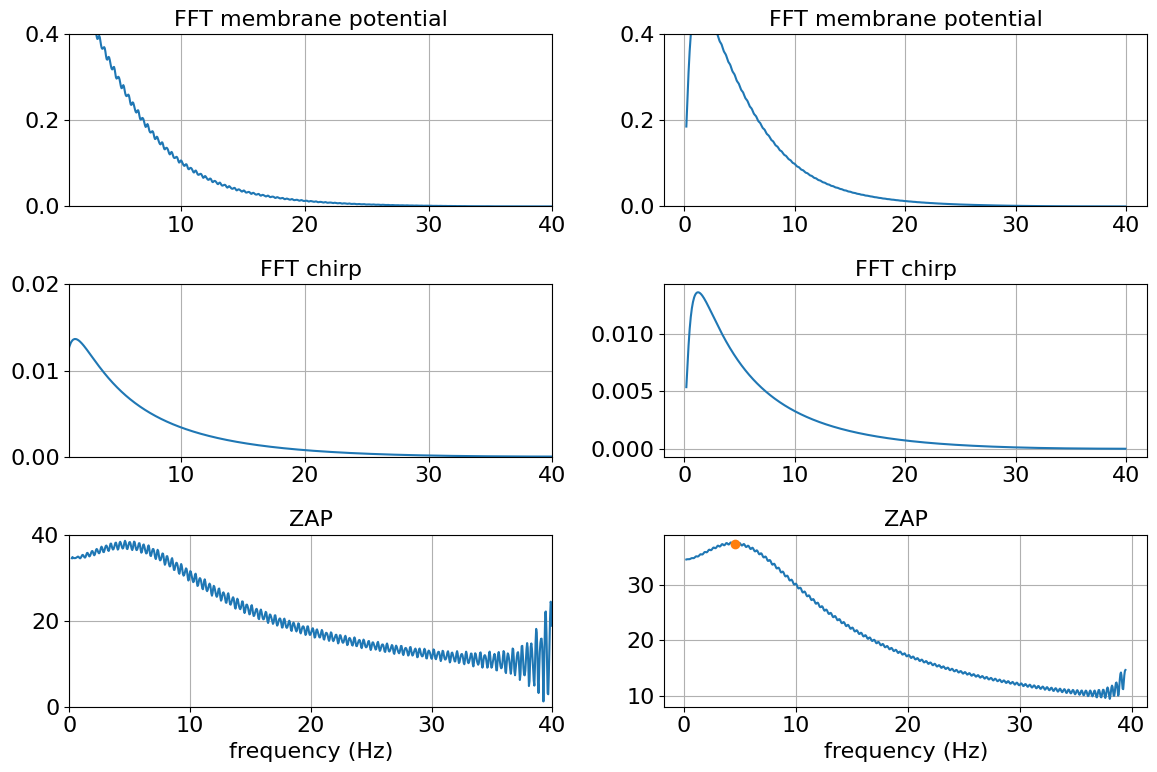

In [79]:
# Kalmbach: impedance amplitude is the ratio between FFT of response and FFT of chirp

from scipy.fft import fft, fftfreq

from scipy.signal import windows
hann_win = windows.hann(len(chirp_signal), len(chirp_signal)*1.)

N = len(v_rec)-1001
T = h.dt/1000
freq = fftfreq(N, T)[:N//2]
lowf = np.argmin(np.abs(freq-0.2))

fft_membr = fft(v_rec.as_numpy()[1:]*hann_win)
fft_chirp = fft(chirp_signal*hann_win)

fft_membr =  2.0/N * np.abs(fft_membr[:N//2])
fft_chirp = 2.0/N * np.abs(fft_chirp[:N//2])


impedance = fft_membr/fft_chirp
zap = np.abs(impedance)
maxf = int(np.where(freq == 40)[0])
zap = zap[:maxf]



fig, ax = plt.subplots(3,2,figsize=(12,8))
ax[0,0].plot(freq[lowf:maxf], fft_membr[lowf:maxf])
ax[0,0].set_xlim([1, 40])
ax[0,0].set_ylim([0, .4])
ax[0,0].grid()
ax[0,0].set_title('FFT membrane potential')

ax[1,0].plot(freq[lowf:maxf], fft_chirp[lowf:maxf])
ax[1,0].set_title('FFT chirp')
ax[1,0].set_xlim([1, 40])
ax[1,0].set_ylim([0, .02])

ax[1,0].grid()

ax[2,0].plot(freq[lowf:maxf], zap[lowf:maxf])
ax[2,0].set_xlabel('frequency (Hz)')
ax[2,0].set_title('ZAP')
ax[2,0].set_xlim([0, 40])
ax[2,0].set_ylim([0, 40])

ax[2,0].grid()


chirp_smooth = np.zeros(fft_chirp.shape[0]-10)
vrec_smooth = np.zeros(fft_membr.shape[0]-10)
zap_smooth = np.zeros(zap.shape[0]-10)

for c in range(len(zap)-10):
    chirp_smooth[c] = np.mean(fft_chirp[c:c+10])
    vrec_smooth[c] = np.mean(fft_membr[c:c+10])
    zap_smooth[c] = np.mean(zap[c:c+10])
    
ax[0,1].plot(freq[lowf:maxf], vrec_smooth[lowf:maxf])
#ax[0,1].set_xlim([.2, 40])
ax[0,1].set_ylim([0, .4])
ax[0,1].grid()
ax[0,1].set_title('FFT membrane potential')

fft_chirp = 2.0/N * np.abs(fft_chirp[:N//2])
ax[1,1].plot(freq[lowf:maxf], chirp_smooth[lowf:maxf])
ax[1,1].set_title('FFT chirp')
#ax[1,1].set_xlim([.2, 40])
#ax[1].set_ylim([0, .02])

ax[1,1].grid()

ax[2,1].plot(freq[lowf:maxf-10], zap_smooth[lowf:maxf])
res_freq = freq[np.argmax(zap_smooth[lowf:maxf])] + 0.2

ax[2,1].plot(res_freq,zap_smooth[np.argmax(zap_smooth[lowf:])], 'o', color='tab:orange')
ax[2,1].set_xlabel('frequency (Hz)')
ax[2,1].set_title('ZAP')
#ax[2,1].set_xlim([.2, 40])
#ax[2].set_ylim([0, 10])
#
ax[2,1].grid()
fig.tight_layout()

#fig.savefig(os.path.join(figpth, 'chirp_freq.png'))


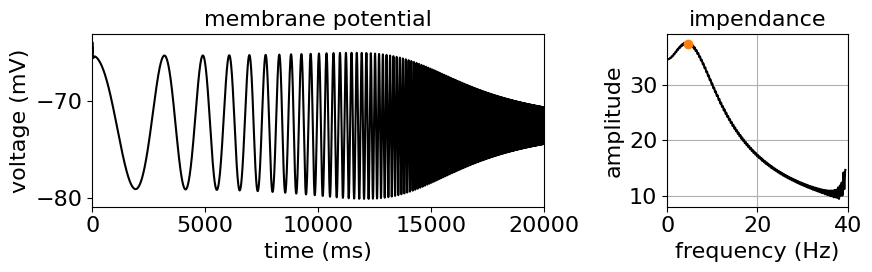

In [80]:
fig, ax = plt.subplots(1,2, figsize=(9,3), width_ratios=[1, 0.4])

ax[0].plot(t_rec, v_rec.as_numpy(), color='k')
ax[0].set_xlabel('time (ms)')
ax[0].set_ylabel('voltage (mV)')
ax[0].set_title('membrane potential')
ax[0].set_xlim([0,20000])
ax[0].set_xticks(np.arange(0, 20001, 5000))

ax[1].plot(freq[lowf:maxf-10], zap_smooth[lowf:maxf], color='k')
res_freq = freq[np.argmax(zap_smooth[lowf:maxf])] + 0.2

ax[1].plot(res_freq,zap_smooth[np.argmax(zap_smooth[lowf:])], 'o', color='tab:orange')
ax[1].set_xlabel('frequency (Hz)')
ax[1].set_title('impendance')
ax[1].set_xlim([0, 40])
ax[1].set_ylabel('amplitude')
ax[1].grid()
fig.tight_layout()

fig.savefig(os.path.join(figpth, 'chirp_freq.png'))
fig.savefig(os.path.join(figpth, 'chirp_freq.svg'), format='svg')

## Summarize all measures

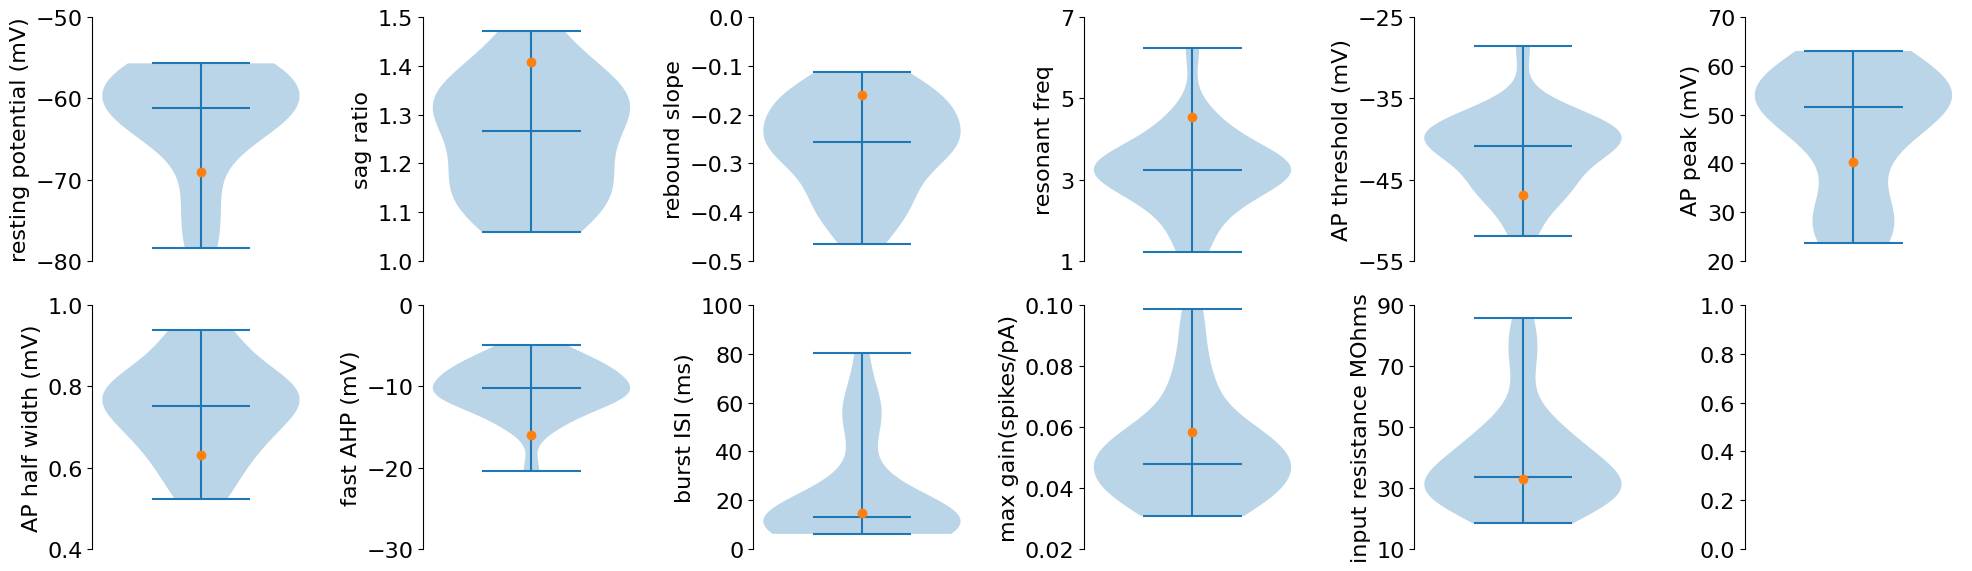

In [81]:
# load Kalmbach data
df = pd.read_csv(os.path.join('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/data','kalmbach_2021_l5_electrophys.csv'))
df['etype'].value_counts() # 1 seems to be the E-type cells

# l5 dataframe
l5df = df[df['etype'] == 1]

# Measures of interest:
# resting potential
# Sag_ratio
# Rebound slope
# Resonant frequency (chirp stimulus)
# AP threshold
# AP peak
# AP Half width
# AP fast afterhyperpolarization
# minimum burst ISI within first 50 ms
# FI_slope
# Inout resistance SSRn

fig, ax = plt.subplots(2,6, figsize=(20,6))


ax = ax.ravel()
ax[0].violinplot(l5df['RMP'], vert=True, showmeans=False,
                  showmedians=True)
ax[0].set_ylim([-80, -50])
ax[0].set_yticks(np.arange(-80, -40, 10))
ax[0].plot(1, rmp, 'o', color='tab:orange')

ax[0].set_ylabel('resting potential (mV)')

ax[1].violinplot(l5df['Sag_ratio'], vert=True, showmeans=False,
                  showmedians=True)
ax[1].set_yticks(np.arange(1, 1.6, 0.1))
ax[1].set_ylim([1, 1.5])

ax[1].plot(1, sag_ratio, 'o', color='tab:orange')

ax[1].set_ylabel('sag ratio')

ax[2].violinplot(l5df['Rebound'], vert=True, showmeans=False,
                  showmedians=True)
ax[2].plot(1,rebound_slope, 'o', color='tab:orange')
ax[2].set_ylim([-0.5, 0])
ax[2].set_yticks(np.arange(-0.5, 0.1, 0.1))
ax[2].set_ylabel('rebound slope')

ax[3].violinplot(l5df['Fr'], vert=True, showmeans=False,
                  showmedians=True)
ax[3].plot(1,res_freq, 'o', color='tab:orange')
ax[3].set_ylim([1, 7])
ax[3].set_yticks(np.arange(1, 9, 2))
ax[3].set_ylabel('resonant freq')

ax[4].violinplot(l5df['AP_threshold'], vert=True, showmeans=False,
                  showmedians=True)
ax[4].plot(1, ap_thresh, 'o', color='tab:orange')
ax[4].set_ylim([-55, -25])
ax[4].set_yticks(np.arange(-55, -15, 10))

ax[4].set_ylabel('AP threshold (mV)')

ax[5].violinplot(l5df['AP_peak'], vert=True, showmeans=False,
                  showmedians=True)
ax[5].plot(1, ap_peak, 'o', color='tab:orange')
ax[5].set_ylim([20,70])
ax[5].set_yticks(np.arange(20, 80, 10))
ax[5].set_ylabel('AP peak (mV)')

ax[6].violinplot(l5df['AP_HW'], vert=True, showmeans=False,
                  showmedians=True)
ax[6].plot(1, ap_hw, 'o', color='tab:orange')

ax[6].set_ylabel('AP half width (mV)')
ax[6].set_ylim([0.4, 1])
ax[6].set_yticks(np.arange(0.4, 1.1, 0.2))
ax[7].violinplot(l5df['f_AHP'], vert=True, showmeans=False,
                  showmedians=True)
ax[7].plot(1, f_AHP, 'o', color='tab:orange')

ax[7].set_ylabel('fast AHP (mV)')
ax[7].set_ylim([-30, 0])
ax[7].set_yticks(np.arange(-30, 1, 10))
ax[8].violinplot(l5df['min_burst_ISI_5'][~np.isnan(l5df['min_burst_ISI_5'])], vert=True, showmeans=False,
                  showmedians=True)
ax[8].plot(1, min_burst_isi, 'o', color='tab:orange')
ax[8].set_ylabel('burst ISI (ms)')
ax[8].set_ylim([0, 100])
ax[8].set_yticks(np.arange(0, 101, 20))

ax[9].violinplot(l5df['FI_slope_max'], vert=True, showmeans=False,
                  showmedians=True)
ax[9].plot(1, max_fi, 'o', color='tab:orange')
ax[9].set_ylabel('max gain(spikes/pA)')
ax[9].set_ylim([0.02, 0.1])
ax[9].set_yticks(np.arange(0.02, 0.11, 0.02))

ax[10].violinplot(l5df['SSRn'], vert=True, showmeans=False,
                  showmedians=True)
ax[10].plot(1, inp_res_max, 'o', color='tab:orange')

ax[10].set_ylabel('input resistance MOhms')
ax[10].set_ylim([10, 90])
ax[10].set_yticks(np.arange(10, 91, 20))
for a in ax:
    a.set_xticks([])
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.spines['bottom'].set_visible(False)
fig.tight_layout()
fig.savefig('l5cell_vs_kalmbach2021.png')

fig.savefig(os.path.join(figpth, 'l5cell_vs_kalmbach2021.svg'), format='svg')
fig.savefig(os.path.join(figpth, 'l5cell_vs_kalmbach2021.png'))


In [82]:
len(l5df)

26

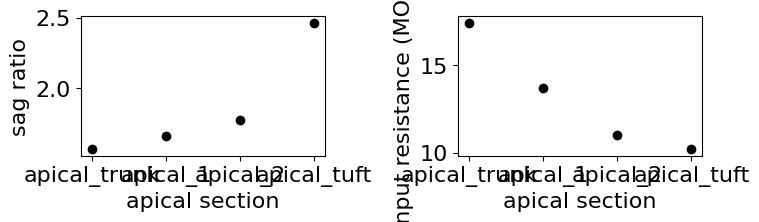

In [83]:
# Beaulieau-Laroche - does voltage sag increase as function of distance from soma?

fig, ax = plt.subplots(1,2, figsize=(8,2.5))

section_names = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
ampl = np.linspace(-.3, -2.0, 20)
sag_ratio = np.zeros((len(section_names), ))
inp_res_max = np.zeros((len(section_names), ))
inp_res_steady = np.zeros((len(section_names), ))

for s, section in enumerate(section_names):

    soma_v = np.zeros((len(ampl),int(1/h.dt*250+1)))
    peak_heights = np.zeros_like(ampl)
    steady_state = np.zeros_like(ampl)
    min_membr_pot = np.zeros_like(ampl)
    
    for i,amp in enumerate(ampl):

        l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
        l5pyr.build()
        l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)


        stim = h.IClamp(l5pyr._nrn_sections[section](0.5))
        stim.delay = 20
        stim.dur = 150
        stim.amp = amp
        clamp_current = h.Vector().record(stim._ref_i)

        t = h.Vector().record(h._ref_t)
        soma_voltg = h.Vector().record(l5pyr._nrn_sections[section](0.5)._ref_v)

        h.celsius = 37
        h.finitialize()
        h.continuerun(250 * ms)

        steady_idx = np.argmin(np.abs(t-150))
        soma_v[i] = soma_voltg.as_numpy()

        # pk = find_peaks(soma_v[i][steady_idx:], height=[-70, 50])
        # if len(pk[1]) > 1:
        #     peak_heights[i] = pk[1]['peak_heights'][0]
        # else:
        #     peak_heights[i] = pk[1]['peak_heights']
        
        min_membr_pot[i] = np.min(soma_v[i])

        steady_state[i] = soma_v[i][steady_idx]


    # Sag ratio - see Methods Kalmbach et al., 2021
    inp_res_max[s] = np.polyfit(ampl,min_membr_pot,1)[0]
    inp_res_steady[s] = np.polyfit(ampl,steady_state,1)[0]

    sag_ratio[s] = inp_res_max[s]/inp_res_steady[s]


ax[0].plot(range(len(section_names)), sag_ratio, 'o', color='k')
ax[0].set_xticks(range(len(section_names)))
ax[0].set_xticklabels(section_names)
ax[1].plot(range(len(section_names)), inp_res_steady, 'o', color='k')


ax[0].set_ylabel('sag ratio')
ax[0].set_xlabel('apical section')

ax[1].set_ylabel('input resistance (MOhms)')
ax[1].set_xlabel('apical section')
ax[1].set_xticks(range(len(section_names)))
ax[1].set_xticklabels(section_names)
fig.savefig(os.path.join(figpth, 'sag_ratio_distance.png'))
fig.tight_layout()

In [84]:
# import matplotlib as mpl
# mpl.rcParams['pdf.fonttype'] = 42
# mpl.rcParams['ps.fonttype'] = 42

# fig = plt.figure(figsize=(16, 6))

# gs = GridSpec(4,5, figure=fig, height_ratios=[1,1,1,1])
# ax = [None]*10
# ax[0] = fig.add_subplot(gs[0, 0])
# ax[1] = fig.add_subplot(gs[1:4, 0])

# c = 2
# for i in np.arange(1,5):
#     ax[c] = fig.add_subplot(gs[0:2, i])
#     ax[c+1] = fig.add_subplot(gs[2:4, i])
#     c += 2

# for c in clamp_current:
#     ax[0].plot(t,c, color='k')

# ax[0].set_ylabel('clamp \n current')
# yticks_v = []
# yticklabels_v = []

# yticks_ca = []
# yticklabels_ca = []

# cv = 0
# cca = 0
# for i,section in enumerate(section_names):
    
#     ax[1].plot(t,voltg[i] + cv, label=section)
#     if section == 'apical_tuft':
#         ax[1].plot(t,np.ones_like(voltg[i]) + cv, color='k', linestyle='-.', linewidth=.5)

#     yticks_v.append(-75+cv)
#     yticks_v.append(50+cv)

#     yticklabels_v.append(str(np.round(-75)))
#     yticklabels_v.append(str(np.round(50)))
#     cv -= 200

# ax[1].legend(loc='lower right')
# ax[1].set_yticks(yticks_v)
# ax[1].set_yticklabels(yticklabels_v)
# ax[1].set_ylabel('voltage $\mu V$')
# ax[1].set_xlabel('time (ms)')

# ax[2].boxplot(l5df['RMP'], vert=True, patch_artist=True, labels=['RMP'])
# ax[2].plot(1, rmp, 'o', color='tab:orange')
# ax[2].set_ylabel('resting potential (mV)')

# ax[3].boxplot(l5df['Sag_ratio'], vert=True, patch_artist=True, labels=['sag_ratio'])
# ax[3].plot(1, sag_ratio, 'o', color='tab:orange')

# ax[3].set_ylabel('sag ratio')

# ax[4].boxplot(l5df['Rebound'], vert=True, patch_artist=True, labels=['rebound'])
# ax[4].plot(1,rebound_slope, 'o', color='tab:orange')
# ax[4].set_ylabel('rebound slope')

# ax[5].boxplot(l5df['Fr'], vert=True, patch_artist=True, labels=['resonance freq'])
# ax[5].plot(1,res_freq, 'o', color='tab:orange')
# ax[5].set_ylabel('resonance freq')

# ax[6].boxplot(l5df['AP_threshold'], vert=True, patch_artist=True, labels=['AP threshold'])
# ax[6].set_ylabel('AP threshold (mV)')
# ax[6].plot(1, ap_thresh, 'o', color='tab:orange')

# ax[7].boxplot(l5df['AP_peak'], vert=True, patch_artist=True, labels=['AP peak'])
# ax[7].set_ylabel('AP peak (mV)')
# ax[7].plot(1, ap_peak, 'o', color='tab:orange')

# ax[8].boxplot(l5df['FI_slope_max'], vert=True, patch_artist=True, labels=['FI slope max'])
# ax[8].set_ylabel('max gain (spikes/pA)')
# ax[8].plot(1, max(smooth_slope)*pA, 'o', color='tab:orange')

# ax[9].boxplot(l5df['SSRn'], vert=True, patch_artist=True, labels=['input resistance'])
# ax[9].set_ylabel('input resistance MOhms')
# ax[9].plot(1, input_resistance_neuron, 'o', color='tab:orange')


# fig.tight_layout()
# fig.savefig('RPPR_L5cell.png')
# fig.savefig('RPPR_L5cell.pdf')